# Data analysis

What the hourly Bitcoin data says **before any model is trained**: statistics of the returns, dependence over time, calendar patterns, market regimes, other markets (Binance, ETH) and macroeconomic variables.

The notebook brings together the analysis parts of the archived notebooks (`old_notebooks/`) and runs them on the base data, `data/btc_hourly.csv.gz`, produced by `hourly-base-data.ipynb` (76,851 consecutive hours, 1 Jan 2018 → 8 Oct 2026). Nothing here reads the old `.npz` windows or the 1-minute Kaggle file.

**Two rules**

- Analyses that can steer a model choice (dependence tests, the AR model, regimes and clusters) use only the **train block (2018 → 2022)** and check themselves out of sample on the **validation block (Jan 2023 → Jun 2024)**. The **test block (Jul 2024 → Oct 2026)** is never used for them. These are the version 2/3 blocks, the split proposed in task 1 of the README.
- Descriptive sections (overview, distribution, drift of the calendar profile, other markets, macro correlation) use the whole series, test block included. Do not use them to choose hyperparameters.

**About the "What we see" texts and the conclusions.** They are copied from the archived notebooks, and each one names its source. Their numbers come from those runs (the old `.npz` data up to 4–5 Oct 2026, the 2018–2023 / 2024+ split of `course-methods.ipynb`, and data from 2017 in the correlation analysis), so small differences are expected. Check them against the outputs after running this notebook.

**Structure**

1. Settings and data.
2. Overview: price, volume and years.
3. Distribution of the returns.
4. Is there anything to predict? Autocorrelation and statistical tests.
5. Calendar patterns, and how they drift.
6. Volatility clustering and market regimes (daily).
7. Other markets: Binance and ETH.
8. Macroeconomic variables.
9. Conclusions.

## 1. Settings and data

Run the notebook from the repo root, so `data/` and `utils/` are found. The helpers come from `utils/` (see the README): statistical tests from `utils/hourly.py`, the daily/weekly/monthly frames from `utils/btc_data.py`, Binance from `utils/binance.py`, and the macro panels and correlation tools from `utils/macro.py` and `utils/correlation.py`.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

sys.path.insert(0, os.getcwd())   # utils/ is in the repo root
from utils import hourly as U
from utils.btc_data import frames_from_hourly, return_summary, plot_return_hists
from utils.binance import load_binance
from utils.macro import load_raw, build_panels
from utils.correlation import (TARGETS, prune_panels, corr_summary, resolve_focus,
                               lead_lag, corr_by_year, heatmap, rolling_corr_plot, cluster_order)

DATA_PATH = os.path.join("data", "btc_hourly.csv.gz")
TRAIN_END = pd.Timestamp("2022-12-31 23:00")   # train block: 2018 -> 2022
VAL_END = pd.Timestamp("2024-06-30 23:00")     # validation block: Jan 2023 -> Jun 2024; test: Jul 2024 ->
ETF_DATE = pd.Timestamp("2024-01-11")          # first trading day of the US spot Bitcoin ETFs
RANDOM_STATE = 42

# Macro correlation (section 8)
START = "2018-01-01"        # same start as the base data
METHOD = "spearman"         # correlation method (robust to fat tails)
PRUNE_THRESHOLD = 0.80      # max |r| allowed between two macro variables
TOP = 12                    # rows shown in each correlation table
FOCUS = ["SP500", "DXY", "US10Y", "Gold", "VIX", "HY_OAS", "NetLiquidity"]  # a-priori shortlist
MAX_LAG = {"D": 4, "W": 8}  # lead-lag range, in periods of each frequency
ROLL_WINDOW = 180           # rolling-correlation window, in daily observations

# Colours and axes style shared by the plots
BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#b4b2a9", "#52514e"


def tidy(ax, title=None):
    if title:
        ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="y", color="#e5e4df", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

`Return` is converted to **percent** (0.4 = +0.4%), the unit used by `utils/hourly.py` and by the model notebooks. The grid check repeats the one of `hourly-base-data.ipynb`: the file must still be one continuous hourly series.

In [2]:
hourly = pd.read_csv(DATA_PATH, index_col="Timestamp", parse_dates=True)
hourly["Return"] *= U.PCT
assert (hourly.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(), "the hourly grid has holes"

r = hourly["Return"]
ONE_HOUR = pd.Timedelta(hours=1)
r_tr = r.loc[:TRAIN_END]
r_va = r.loc[TRAIN_END + ONE_HOUR:VAL_END]
r_te = r.loc[VAL_END + ONE_HOUR:]

print(f"{len(hourly):,} hours   {hourly.index[0]} -> {hourly.index[-1]}")
for name, s in [("train", r_tr), ("val", r_va), ("test", r_te)]:
    print(f"  {name:<5} {len(s):>6,} hours  {s.index[0]} -> {s.index[-1]}   average |hourly move| {s.abs().mean():.3f}%")
print(f"no_trade hours: {hourly['no_trade'].sum()}, hours with at least one filled minute: {(hourly['filled_minutes'] > 0).mean():.1%}")

76,851 hours   2018-01-01 00:00:00 -> 2026-10-08 02:00:00
  train 43,824 hours  2018-01-01 00:00:00 -> 2022-12-31 23:00:00   average |hourly move| 0.495%
  val   13,128 hours  2023-01-01 00:00:00 -> 2024-06-30 23:00:00   average |hourly move| 0.300%
  test  19,899 hours  2024-07-01 00:00:00 -> 2026-10-08 02:00:00   average |hourly move| 0.319%
no_trade hours: 10, hours with at least one filled minute: 36.9%


The 10 `no_trade` hours (exchange outages) carry a made-up 0% return, and the hour after each outage carries the whole move. They are kept: they are 0.01% of the hours, too few to change the statistics below, and removing them would break the hourly grid that the autocorrelations rely on.

## 2. Overview: price, volume and years

The price on a log scale (equal vertical distances are equal percentage moves) with the traded volume below it. The dashed lines mark the start of the validation and test blocks.

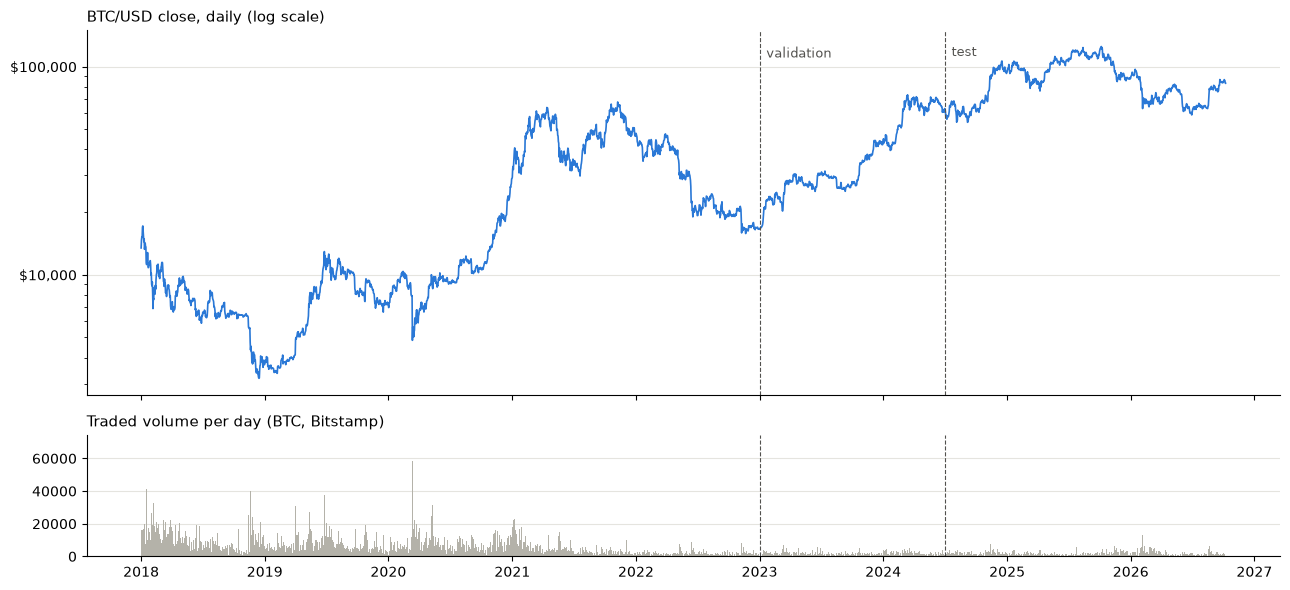

In [3]:
daily = hourly.resample("D").agg({"Close": "last", "Volume": "sum"})

fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax[0].plot(daily.index, daily["Close"], color=BLUE, lw=1.2)
ax[0].set_yscale("log")
ax[0].yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("${x:,.0f}"))
ax[1].bar(daily.index, daily["Volume"], width=1.0, color=GREY)
for a in ax:
    for t in (TRAIN_END, VAL_END):
        a.axvline(t + ONE_HOUR, color=INK, lw=0.8, ls="--")
for t, label in [(TRAIN_END, "validation"), (VAL_END, "test")]:
    ax[0].text(t + pd.Timedelta(days=20), daily["Close"].max(), label, color=INK, fontsize=9, va="top")
tidy(ax[0], "BTC/USD close, daily (log scale)")
tidy(ax[1], "Traded volume per day (BTC, Bitstamp)")
plt.tight_layout()
plt.show()

**The years.** One row per calendar year: the average size of an hourly move, its standard deviation and excess kurtosis (fat tails), the share of up hours and up days, the price change over the year, and the outage hours. Daily returns are compounded from the hourly ones and only complete days are counted.

In [4]:
years = r.index.year
hours_per_day = r.resample("D").count()
d_ret = ((1 + r / U.PCT).resample("D").prod() - 1)[hours_per_day == 24] * U.PCT

yearly = pd.DataFrame({
    "hours": r.groupby(years).size(),
    "mean_abs_return_%": r.abs().groupby(years).mean(),
    "std_%": r.groupby(years).std(),
    "excess_kurtosis": r.groupby(years).apply(lambda s: s.kurt()),
    "up_hours": (r > 0).groupby(years).mean(),
    "up_days": (d_ret > 0).groupby(d_ret.index.year).mean(),
    "price_change_%": ((1 + r / U.PCT).groupby(years).prod() - 1) * U.PCT,
    "no_trade_hours": hourly["no_trade"].groupby(years).sum(),
})
yearly.index.name = "year"
yearly.round(3)

,hours,mean_abs_return_%,std_%,excess_kurtosis,up_hours,up_days,price_change_%,no_trade_hours
year,,,,,,,,
2018,8760,0.574,0.987,13.551,0.497,0.490,-73.391,0
2019,8760,0.412,0.738,32.005,0.511,0.515,94.091,0
2020,8784,0.436,0.820,127.944,0.515,0.579,304.455,4
2021,8760,0.623,0.935,13.875,0.507,0.510,59.400,0
2022,8760,0.430,0.686,11.802,0.497,0.463,-64.236,2
2023,8760,0.269,0.454,25.781,0.511,0.496,155.675,1
2024,8784,0.370,0.564,7.467,0.512,0.525,120.978,2
2025,8760,0.307,0.476,12.408,0.503,0.501,-6.302,1
2026,6723,0.297,0.459,10.059,0.496,0.486,-5.005,0


**The price level is not stationary.** Prices from the later years lie far outside the range of the train block. The cell measures how much of the validation and test hours trade above the highest train price.

In [5]:
close = hourly["Close"]
train_max = close.loc[:TRAIN_END].max()
print(f"Close in the train block: {close.loc[:TRAIN_END].min():,.0f} to {train_max:,.0f} USD")
for name, s in [("validation", close.loc[TRAIN_END + ONE_HOUR:VAL_END]), ("test", close.loc[VAL_END + ONE_HOUR:])]:
    print(f"  {name:<10}: {s.min():,.0f} to {s.max():,.0f} USD, above the train maximum {(s > train_max).mean():.1%} of the hours")

Close in the train block: 3,140 to 68,627 USD
  validation: 16,504 to 73,608 USD, above the train maximum 6.0% of the hours
  test      : 49,814 to 126,111 USD, above the train maximum 72.1% of the hours


**What we see** *(text copied from the archived notebooks)*

- *Price evolution* (`data-preparation.ipynb`): "Starting in 2020, the asset entered a new bull cycle driven by institutional adoption, reaching new all-time highs in 2021. After a correction in 2022, the price resumed its upward trend from 2023 onward, surpassing $100,000 at the most recent peak visible in the chart, followed by a consolidation/correction phase around $75,000–$80,000."
- *The blocks* (`bitcoin-models-2018-2026.ipynb`, decision d): "Calendar years are easy to explain. Train keeps 5 full years with both bull and bear markets (2018 crash, 2020–2021 bull, 2022 crash). Validation (1.5 years) is long enough to judge hyperparameters. Test (≈2.25 years, ≈820 independent days) is long enough for a meaningful significance test of direction accuracy."
- *Volatility changes a lot between periods* (`bitcoin-models-new-data.ipynb`, decision c): "The test period is calmer than most of the training period, so raw error values are not comparable between periods. **Decision:** always report errors *relative to a baseline* (the 'skill' metrics) in addition to raw values." In version 3 the average hourly move was 0.485% in train, 0.301% in validation and 0.320% in test.
- *The price level* (`bitcoin-models-new-data.ipynb`, decision a): "Standardizing with one global mean and standard deviation does not remove the trend. The scaled Close in the test period (about 1 to 7.6) lies mostly *above* anything seen in training (max about 3.8). Tree models cannot predict outside the range they were trained on: every test window would look like 'the highest price ever seen'. Linear models would extrapolate the price level in a meaningless way. **Decision:** build *scale-free* features (returns, ratios, volatility)."

## 3. Distribution of the returns

Log returns at four timeframes: hourly, daily, weekly and monthly. The daily, weekly and monthly candles are built from the base series with `frames_from_hourly` (incomplete periods at the end are dropped). For a normal distribution the excess kurtosis would be 0.

,start,n,mean,std,skew,excess_kurtosis,min,max
H,2018-01-01,76850,0.002349,0.71207,-0.102144,40.608654,-18.090334,20.548271
D,2018-01-01,3201,0.056971,3.426285,-1.039313,16.638303,-49.396946,17.772991
W,2018-01-07,456,0.36841,8.823307,-0.549347,2.374874,-40.773813,25.604709
ME,2018-01-31,104,2.027135,18.520436,-0.109189,0.258458,-46.632483,48.376315


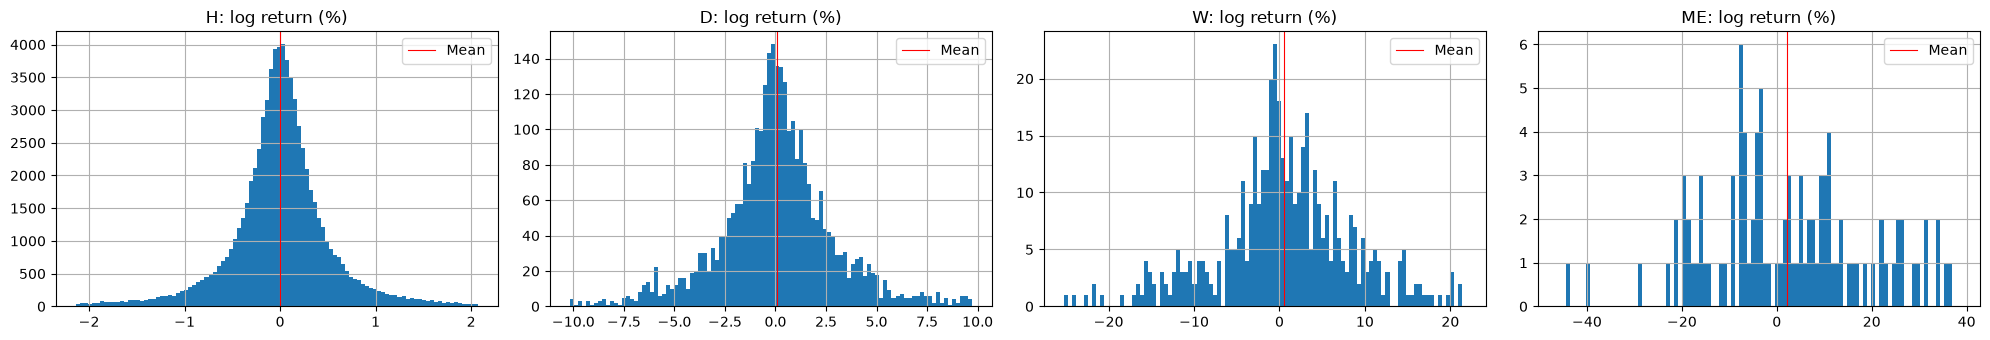

In [6]:
frames = {"H": hourly, **frames_from_hourly(hourly)}
display(return_summary(frames).round(3))
plot_return_hists(frames)
plt.show()

**Mean return per timeframe** *(from the first version of the correlation notebook, `old_notebooks/correlation_analyses.ipynb`)*. "For investigating possible correlations between the BTC price and other variables it is important to take into consideration the different timescales these changes may manifest themselves in." The table gives the mean change of each timeframe and its **daily equivalent** (the mean divided by the days in one period), so the timeframes can be compared. Changes are compounded from the hourly returns; the first and last periods are dropped because they may be incomplete.

In [7]:
TIMEFRAMES = {"hourly": ("h", 1 / 24), "12 hours": ("12h", 0.5), "daily": ("D", 1), "3 days": ("3D", 3),
              "weekly": ("W", 7), "2 weeks": ("2W", 14), "monthly": ("ME", 30), "3 months": ("3ME", 90)}
tf_rows = {}
for name, (rule, days_per_period) in TIMEFRAMES.items():
    pct = ((1 + r / U.PCT).resample(rule).prod() - 1) * U.PCT
    if rule != "h":
        pct = pct.iloc[1:-1]
    tf_rows[name] = {"periods": len(pct), "mean_%": pct.mean(), "daily_equivalent_%": pct.mean() / days_per_period,
                     "median_%": pct.median(), "std_%": pct.std(), "up_share": (pct > 0).mean()}
pd.DataFrame(tf_rows).T.round(3)

,periods,mean_%,daily_equivalent_%,median_%,std_%,up_share
hourly,76851.0,0.005,0.117,0.005,0.712,0.506
12 hours,6403.0,0.056,0.113,0.046,2.354,0.517
daily,3201.0,0.115,0.115,0.033,3.387,0.508
3 days,1066.0,0.330,0.110,0.051,5.769,0.510
weekly,456.0,0.754,0.108,0.269,8.733,0.522
2 weeks,228.0,1.633,0.117,1.291,13.348,0.535
monthly,104.0,3.785,0.126,1.735,19.214,0.529
3 months,34.0,11.285,0.125,0.965,38.940,0.500


**What we see** *(`old_notebooks/correlation_analyses.ipynb`, data 2012–2026)* The daily equivalent of the mean was about the same from 30 minutes to 2 weeks (0.26–0.31% per day) and rose to 0.32% for monthly and 0.36% for 3-month changes. A mean of compounded returns is not exactly proportional to the length of the period, so small differences between timeframes are expected. Compare the mean with the median and the share of up periods: a mean far above the median means that a few large moves drive it.

**How fat are the tails?** The Jarque–Bera test checks whether skewness and kurtosis match a normal distribution. The table also compares the share of returns more than 3 and 5 standard deviations from the mean with what a normal distribution would give.

,n,Jarque-Bera,p-value,share |z| > 3,normal |z| > 3,share |z| > 5,normal |z| > 5
H,"76,850","5,279,863",0.0e+00,1.93%,0.27%,0.439%,0.00006%
D,"3,201","37,375",0.0e+00,1.69%,0.27%,0.125%,0.00006%
W,456,126,3.5e-28,0.88%,0.27%,0.000%,0.00006%
ME,104,0,8.4e-01,0.00%,0.27%,0.000%,0.00006%


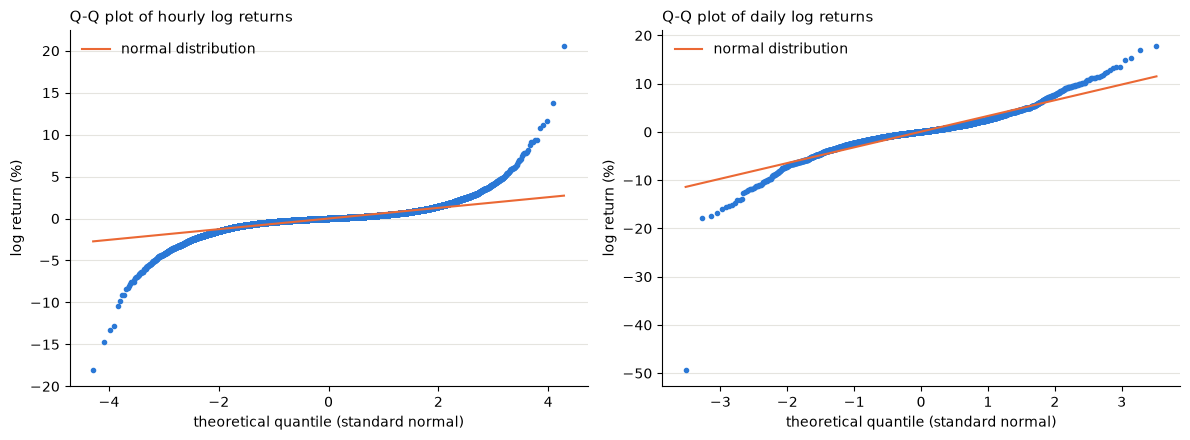

In [8]:
tail_rows = {}
for f, df in frames.items():
    lr = 100 * np.log(df["Close"]).diff().dropna()
    z = (lr - lr.mean()) / lr.std()
    jb = stats.jarque_bera(lr)
    tail_rows[f] = {"n": len(lr), "Jarque-Bera": jb.statistic, "p-value": jb.pvalue,
                    "share |z| > 3": (z.abs() > 3).mean(), "normal |z| > 3": 2 * stats.norm.sf(3),
                    "share |z| > 5": (z.abs() > 5).mean(), "normal |z| > 5": 2 * stats.norm.sf(5)}
display(pd.DataFrame(tail_rows).T.style.format(
    {"n": "{:,.0f}", "Jarque-Bera": "{:,.0f}", "p-value": "{:.1e}", "share |z| > 3": "{:.2%}",
     "normal |z| > 3": "{:.2%}", "share |z| > 5": "{:.3%}", "normal |z| > 5": "{:.5%}"}))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, f, name in [(ax[0], "H", "hourly"), (ax[1], "D", "daily")]:
    lr = 100 * np.log(frames[f]["Close"]).diff().dropna()
    (osm, osr), (slope, intercept, _) = stats.probplot(lr, dist="norm")
    a.plot(osm, osr, "o", ms=3, color=BLUE)
    a.plot(osm, slope * osm + intercept, color=ORANGE, lw=1.5, label="normal distribution")
    a.set_xlabel("theoretical quantile (standard normal)")
    a.set_ylabel("log return (%)")
    a.legend(frameon=False)
    tidy(a, f"Q-Q plot of {name} log returns")
plt.tight_layout()
plt.show()

**The largest hourly moves.** If an outage or a data error were driving the tails, it would show up here.

In [9]:
largest = r.abs().nlargest(15).index
hourly.loc[largest, ["Open", "Close", "Volume", "Return", "filled_minutes"]].sort_index()

,Open,Close,Volume,Return,filled_minutes
Timestamp,,,,,
2018-02-06 09:00:00,6090.15,6670.00,4492.564149,9.520033,0
2018-04-12 11:00:00,6935.90,7725.77,6147.111395,11.397134,0
2019-04-02 04:00:00,4174.83,4671.75,3798.250505,11.846500,1
2019-07-18 14:00:00,9417.33,10307.18,3395.766471,9.498252,0
2019-10-26 01:00:00,9217.64,10110.42,5907.924218,9.762961,0
2020-03-12 10:00:00,7342.49,6334.44,6856.299515,-13.728994,0
2020-03-12 23:00:00,5798.25,4841.67,8051.447101,-16.548398,0
2020-03-13 01:00:00,4671.14,4111.78,2209.176426,-11.979141,0
2020-03-13 02:00:00,4115.92,5049.75,5532.585803,22.811775,0


**What we see** *(README, data quality check of 18 Oct, on data from 2017; `hourly-base-data.ipynb` finds 9 hours above 10% since 2018)*

"Only 0.2% of hours have exactly 0% change. There are 13 hours with moves above 10%, and all of them are real events (COVID crash of 12–13 Mar 2020, crash of 19 May 2021, the ETF rejection of Mar 2017, Musk's tweet of 29 Jan 2021), not data errors. Hourly returns have very fat tails (excess kurtosis 35.7). **The data is clean. The noise is the market itself, not a data-quality problem**, so it cannot be 'cleaned away'. It can only be handled with robust losses, volatility scaling and aggregated targets."

*(`Correlation Analyses/correlation_analyses.ipynb`)* "Heavy tails (high excess kurtosis) are one reason the correlations use Spearman." On the 2012–2026 data the excess kurtosis was 25.4 for daily, 4.1 for weekly and 11.4 for monthly log returns.

*(`model_test.ipynb`, README)* For the RNN/LSTM: "the MSE loss is dominated by the few extreme hours".

## 4. Is there anything to predict?

*Section and texts from `bitcoin-models-v3.ipynb` (A1). Train block only.*

**Autocorrelation** (ACF) at lag *k* is the correlation between the value of an hour and the value *k* hours earlier. If returns were predictable from their own past, some autocorrelations would be clearly different from 0. Three series are examined:

- the **returns** *r* (direction and size together),
- the **absolute returns** |*r*| (only the size of the move),
- the **squared returns** *r*² (size, with more weight on big moves).

The dashed lines show ±1.96/√n: values outside them are significant at 5% if the true correlation were 0.

The **Ljung–Box test** checks whether the first 24 autocorrelations are *jointly* zero. A tiny p-value means "there is some dependence".

A significant correlation is not the same as a useful one. The share of variance that a *linear* model of the last 24 returns can explain is checked directly by fitting an AR(24) model (a linear regression on the last 24 returns) on the train block and testing it on the validation block.

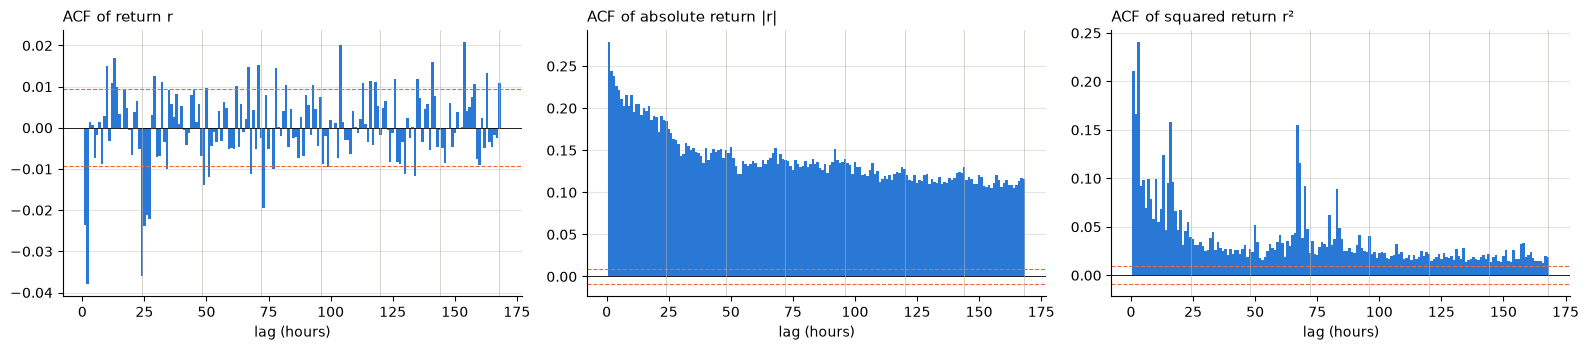

,Q (24 lags),p-value,ACF lag 1,ACF lag 24,sum of ACF² lags 1-24
return r,194.2876,0.0,-0.0237,-0.0359,0.0044
|r|,45365.2354,0.0,0.2785,0.1842,1.0349
r²,11840.1823,0.0,0.2110,0.0393,0.2701


n = 43,824 hours, significance band ±0.0094


In [10]:
LAGS = 168


def acf(x, lags):
    x = np.asarray(x, float) - np.mean(x)
    den = (x ** 2).sum()
    return np.array([(x[k:] * x[:-k]).sum() / den for k in range(1, lags + 1)])


acfs = {"return r": acf(r_tr, LAGS), "absolute return |r|": acf(r_tr.abs(), LAGS), "squared return r²": acf(r_tr ** 2, LAGS)}
band = 1.96 / np.sqrt(len(r_tr))
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
for a, (name, v) in zip(ax, acfs.items()):
    a.bar(range(1, LAGS + 1), v, width=1.0, color=BLUE)
    a.axhline(band, ls="--", c=ORANGE, lw=0.8)
    a.axhline(-band, ls="--", c=ORANGE, lw=0.8)
    a.axhline(0, c="k", lw=0.6)
    for d in range(24, LAGS + 1, 24):
        a.axvline(d, c=GREY, lw=0.4)
    a.set_xlabel("lag (hours)")
    tidy(a, f"ACF of {name}")
plt.tight_layout()
plt.show()

lb = pd.DataFrame({name: dict(zip(["Q (24 lags)", "p-value"], U.ljung_box(x, 24)))
                   for name, x in [("return r", r_tr), ("|r|", r_tr.abs()), ("r²", r_tr ** 2)]}).T
lb["ACF lag 1"] = [v[0] for v in acfs.values()]
lb["ACF lag 24"] = [v[23] for v in acfs.values()]
lb["sum of ACF² lags 1-24"] = [(v[:24] ** 2).sum() for v in acfs.values()]
display(lb.round(4))
print(f"n = {len(r_tr):,} hours, significance band ±{band:.4f}")

In [11]:
# AR(24): linear regression of each hour's return on the 24 previous returns
def lag_matrix(x, k=24):
    x = np.asarray(x)
    return np.column_stack([x[k - j - 1: len(x) - j - 1] for j in range(k)]), x[k:]


Xa, ya = lag_matrix(r_tr)
Xv, yv = lag_matrix(r_va)
for name, target_tr, target_va in [("return r", ya, yv), ("absolute return |r|", np.abs(ya), np.abs(yv))]:
    Xa_, Xv_ = (Xa, Xv) if name == "return r" else (np.abs(Xa), np.abs(Xv))
    ar = Ridge(alpha=1e-6).fit(Xa_, target_tr)
    ins, oos = U.r2(target_tr, ar.predict(Xa_)), U.r2(target_va, ar.predict(Xv_))
    ins0, oos0 = U.r2_oos(target_tr, ar.predict(Xa_)), U.r2_oos(target_va, ar.predict(Xv_))
    print(f"AR(24) on {name:<20}: R² train {ins:+.4f}  validation {oos:+.4f}   "
          f"(R²_oos vs zero: train {ins0:+.4f}, validation {oos0:+.4f})")

AR(24) on return r            : R² train +0.0046  validation -0.0017   (R²_oos vs zero: train +0.0046, validation -0.0012)
AR(24) on absolute return |r| : R² train +0.1844  validation +0.1037   (R²_oos vs zero: train +0.4665, validation +0.4388)


**What we see** *(`bitcoin-models-v3.ipynb`)*

- **Returns (left plot).** Almost all autocorrelations are inside the significance band. A few small negative ones stand out: lag 1 (−0.024), lag 2 and lag 24 (−0.035). These are small **reversals**: after a move, the next hour (and the same hour next day) tends to move slightly the other way. The Ljung–Box test rejects "no dependence" (p ≈ 0), so the effect is real. But it is tiny: the sum of the squared autocorrelations over 24 lags is **0.004**, which means a linear model of the last 24 returns can explain at most ≈0.4% of the variance. The AR(24) model confirms it: R² +0.004 on the train block, **−0.002 on validation**. The dependence is too weak and too unstable to be used.
- **Size of the move (middle plot).** The absolute returns are strongly autocorrelated: 0.27 at lag 1 and still ≈0.10 a full week later (*volatility clustering*, with a long memory). The AR(24) model on |r| explains **10.5% of the validation variance**. (This number is for 1 hour ahead; predicting 1–24 hours ahead is harder.)
- **Squared returns (right plot).** Same message, but noisier: squaring gives enormous weight to a few extreme hours (the isolated spikes, e.g. around lag 67, come from a handful of crash hours). This is why the absolute value |r| is used as the hourly volatility target.

**Is the reversal stable from year to year?** Version 3 called the reversal unstable; `v3-extensions.ipynb` later found that the lag-1 reversal still gives a small direction signal for the next hour. The table repeats the main numbers for each year of the train and validation blocks (the test block is left out).

In [12]:
r_tv = r.loc[:VAL_END]
acf_years = {}
for y, s in r_tv.groupby(r_tv.index.year):
    a_r, a_abs = acf(s, 24), acf(s.abs(), 24)
    acf_years[y] = {"ACF r lag 1": a_r[0], "ACF r lag 2": a_r[1], "ACF r lag 24": a_r[23],
                    "Ljung-Box p (r, 24 lags)": U.ljung_box(s, 24)[1],
                    "ACF |r| lag 1": a_abs[0], "ACF |r| lag 24": a_abs[23]}
display(pd.DataFrame(acf_years).T.round(4))

,ACF r lag 1,ACF r lag 2,ACF r lag 24,"Ljung-Box p (r, 24 lags)",ACF |r| lag 1,ACF |r| lag 24
2018,-0.0323,-0.0584,-0.0331,0.0000,0.2553,0.2206
2019,0.0036,-0.0328,-0.0539,0.0000,0.2204,0.1626
2020,-0.0760,-0.0453,-0.0243,0.0000,0.3570,0.1453
2021,-0.0042,-0.0289,-0.0447,0.0000,0.2196,0.1328
2022,-0.0002,-0.0099,-0.0214,0.2496,0.2808,0.1772
2023,-0.0378,0.0285,-0.0225,0.0000,0.2413,0.0997
2024,0.0004,-0.0286,-0.0068,0.0176,0.2960,0.1334


**What we see** *(`v3-extensions.ipynb`, section 5, on the test block, which this notebook does not use)*

"**The reversal is stable.** On Alberto's test block (Jul 2024 → Oct 2026) the simple rule still has AUC **0.528**, and its 10% most confident forecasts are right **54.6%** of the time (p = 3×10⁻⁵). This is a real but small effect for **one hour ahead only**: about 55 correct out of 100 confident calls, before any trading costs."

## 5. Calendar patterns, and how they drift

*Section and texts from `bitcoin-models-v3.ipynb` (A1). Train block only.*

**Calendar patterns.** Does the time of day or the day of the week matter? The plots show the average return and the average *size* of the move for every hour of the day (UTC) and every weekday, with 95% confidence intervals (train block).

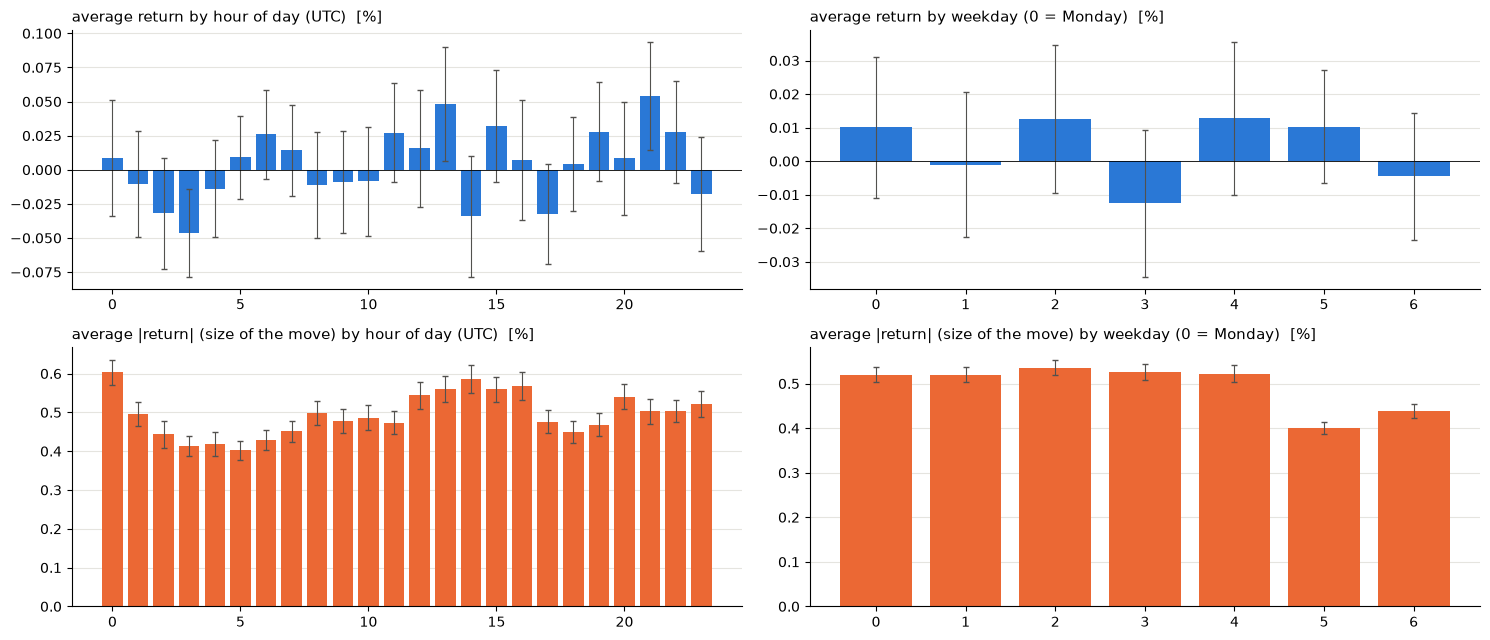

|r| by hour: lowest 0.403% at 5:00, highest 0.603% at 0:00 (ratio 1.50)
|r| weekend / weekdays: 0.80
ANOVA 'mean return equal for all 24 hours': p = 0.012  |  'mean |r| equal for all hours': p = 8.9e-48


In [13]:
cal = pd.DataFrame({"r": r_tr, "abs": r_tr.abs(), "hour": r_tr.index.hour, "dow": r_tr.index.dayofweek})
fig, ax = plt.subplots(2, 2, figsize=(15, 6.5))
for j, key in enumerate(["hour", "dow"]):
    g = cal.groupby(key)
    for i, col in enumerate(["r", "abs"]):
        m, se = g[col].mean(), g[col].std() / np.sqrt(g[col].count())
        ax[i, j].bar(m.index, m.values, yerr=1.96 * se.values, capsize=2, color=BLUE if col == "r" else ORANGE,
                     error_kw={"ecolor": INK, "lw": 0.8})
        ax[i, j].axhline(0, c="k", lw=0.6)
        tidy(ax[i, j], f"{'average return' if col == 'r' else 'average |return| (size of the move)'} by "
                       f"{'hour of day (UTC)' if key == 'hour' else 'weekday (0 = Monday)'}  [%]")
plt.tight_layout()
plt.show()

prof = cal.groupby("hour")["abs"].mean()
print(f"|r| by hour: lowest {prof.min():.3f}% at {prof.idxmin()}:00, highest {prof.max():.3f}% at {prof.idxmax()}:00 "
      f"(ratio {prof.max() / prof.min():.2f})")
wk = cal.groupby("dow")["abs"].mean()
print(f"|r| weekend / weekdays: {wk[5:].mean() / wk[:5].mean():.2f}")
t_hour = stats.f_oneway(*[g.values for _, g in cal.groupby("hour")["r"]])
t_hour_abs = stats.f_oneway(*[g.values for _, g in cal.groupby("hour")["abs"]])
print(f"ANOVA 'mean return equal for all 24 hours': p = {t_hour.pvalue:.3f}  |  "
      f"'mean |r| equal for all hours': p = {t_hour_abs.pvalue:.1e}")

**What we see in the calendar** *(`bitcoin-models-v3.ipynb`)*

- **Average return by hour:** the bars are all close to 0 and most confidence intervals cross 0. The ANOVA test gives p = 0.011, so some hours differ slightly on average, but the differences are tiny compared with the size of an hourly move (≈0.5%).
- **Size of the move by hour:** a very clear pattern (p ≈ 10⁻⁴⁸). Moves at 00:00 UTC (the daily candle close) are **1.5×** larger than at 05:00 UTC, the quietest hour. Weekend hours move only **0.81×** as much as weekday hours.

**Does the daily rhythm drift?** *(descriptive, whole series)* `v3-extensions.ipynb` reported that "the daily rhythm of volatility changed after 2024 (the 14 UTC peak grew from 1.2× to 1.7× the average hour, probably because of the US spot ETFs)". The original analysis (`hourly-move-size.ipynb`) was deleted, so it is rebuilt here: the size of the move in each hour divided by the average hour, per year, and before and after the first ETF trading day.

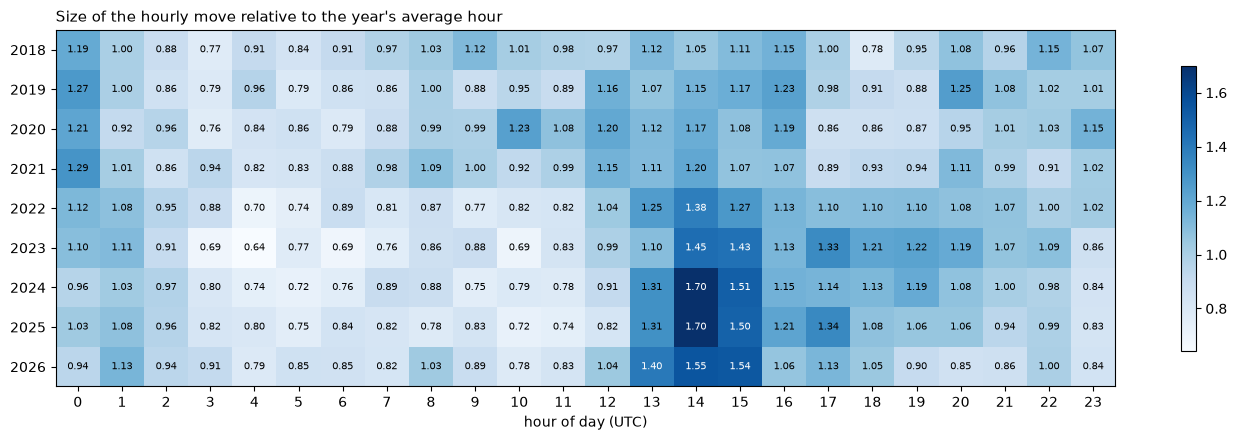

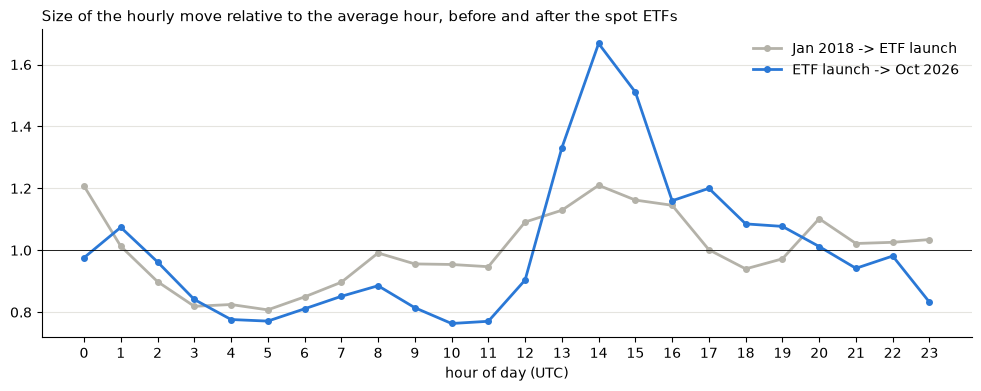

Timestamp,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Jan 2018 -> ETF launch,1.21,1.01,0.90,0.82,0.82,0.81,0.85,0.90,0.99,0.96,...,1.21,1.16,1.15,1.0,0.94,0.97,1.10,1.02,1.03,1.03
ETF launch -> Oct 2026,0.98,1.07,0.96,0.84,0.78,0.77,0.81,0.85,0.89,0.81,...,1.67,1.51,1.16,1.2,1.09,1.08,1.01,0.94,0.98,0.83


|r| weekend / weekdays by year: {2018: 0.83, 2019: 0.88, 2020: 0.8, 2021: 0.82, 2022: 0.66, 2023: 0.59, 2024: 0.57, 2025: 0.6, 2026: 0.58}


In [14]:
a = r.abs()
rel_hour = a.groupby([a.index.year, a.index.hour]).mean().unstack()
rel_hour = rel_hour.div(rel_hour.mean(axis=1), axis=0)          # 1 = the average hour of that year

fig, ax = plt.subplots(figsize=(14, 4.5))
im = ax.imshow(rel_hour.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(24))
ax.set_yticks(range(len(rel_hour)))
ax.set_yticklabels(rel_hour.index)
for i in range(rel_hour.shape[0]):
    for j in range(rel_hour.shape[1]):
        v = rel_hour.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 1.35 else "black")
ax.set_xlabel("hour of day (UTC)")
ax.set_title("Size of the hourly move relative to the year's average hour", loc="left", fontsize=11)
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

periods = {"Jan 2018 -> ETF launch": a.loc[:ETF_DATE - ONE_HOUR], "ETF launch -> Oct 2026": a.loc[ETF_DATE:]}
etf_prof = pd.DataFrame({k: s.groupby(s.index.hour).mean() / s.mean() for k, s in periods.items()})
fig, ax = plt.subplots(figsize=(12, 4))
for (k, col), c in zip(etf_prof.items(), [GREY, BLUE]):
    ax.plot(etf_prof.index, col, marker="o", ms=4, lw=2, color=c, label=k)
ax.axhline(1, c="k", lw=0.6)
ax.set_xticks(range(24))
ax.set_xlabel("hour of day (UTC)")
ax.legend(frameon=False)
tidy(ax, "Size of the hourly move relative to the average hour, before and after the spot ETFs")
plt.show()
display(etf_prof.T.round(2))

weekend = a.groupby([a.index.year, a.index.dayofweek >= 5]).mean().unstack()
print("|r| weekend / weekdays by year:", (weekend[True] / weekend[False]).round(2).to_dict())

**What we see** *(`v3-extensions.ipynb`, conclusions)*

"Bitcoin's behaviour drifts (e.g. the new 14 UTC volatility peak since the ETFs), so **keeping models and calibrations up to date matters more than extra data sources**." Refitting every month with a 12-month half-life raised the R² of the hourly move size from 0.124 to 0.148, better in 28 of 29 test months.

**Conclusion of A1, the answer to "why does it look like noise?"** *(`bitcoin-models-v3.ipynb`)*
The **direction** of the next hours is almost pure noise: the only dependence is a tiny reversal effect that explains well under 1% of the variance. No model can turn that into a visible MAE improvement. The **size** of the next hours is clearly predictable from recent volatility, the hour of the day and the weekday. So the problem is not the models: the hourly return target asks the one question the data cannot answer.

## 6. Volatility clustering and market regimes (daily)

*Section and texts from `course-methods.ipynb`. One forecast per day, at 23:00, for the next 24 hours. Statistics, correlations and clusters are fitted on the train days; the validation days check them. (`course-methods.ipynb` used train 2018–2023 and test 2024+; here the common blocks are used.)*

**Attributes.** Each attribute describes the last day or the last week, and only uses hours up to the moment of the forecast:

| Attribute | Meaning |
|---|---|
| `ret_1d`, `ret_7d`, `ret_30d` | price change over the last 24 h, 7 days and 30 days (%) |
| `size_1d` | average size of the hourly changes over the last 24 h (mean \|change\|) |
| `vol_1d`, `vol_7d` | standard deviation of the hourly changes over the last 24 h / 7 days |
| `range_1d` | distance between the highest and the lowest price of the last 24 h (%) |
| `volume_ratio` | traded volume of the last 24 h compared with the weekly average (log) |
| `last_hour` | the change in the last hour |

**Targets.** `size_next`: average \|hourly change\| of the next 24 h. `ret_next`: change over the next 24 h. `up_next`: 1 if the price is higher after 24 h. `shift(-24)` takes values from the future, so these columns are only used as answers, never as inputs.

In [15]:
volume = hourly["Volume"].clip(lower=0)
attributes = pd.DataFrame({
    "ret_1d": (close / close.shift(24) - 1) * 100,
    "ret_7d": (close / close.shift(168) - 1) * 100,
    "ret_30d": (close / close.shift(720) - 1) * 100,
    "size_1d": r.abs().rolling(24).mean(),
    "vol_1d": r.rolling(24).std(),
    "vol_7d": r.rolling(168).std(),
    "range_1d": (hourly["High"].rolling(24).max() / hourly["Low"].rolling(24).min() - 1) * 100,
    "volume_ratio": np.log1p(volume.rolling(24).mean()) - np.log1p(volume.rolling(168).mean()),
    "last_hour": r,
})
attributes["size_next"] = r.abs().rolling(24).mean().shift(-24)
attributes["ret_next"] = (close.shift(-24) / close - 1) * 100
attributes["up_next"] = (attributes["ret_next"] > 0).astype(int)
num_cols = ["ret_1d", "ret_7d", "ret_30d", "size_1d", "vol_1d", "vol_7d", "range_1d", "volume_ratio", "last_hour"]

# one forecast per day at 23:00; drop the first 30 days (no history yet) and the last day (no answer yet)
days = attributes[attributes.index.hour == 23].dropna()
target_end = days.index + pd.Timedelta(hours=24)
train_days = days[target_end <= TRAIN_END]                               # the next 24 h are inside train
val_days = days[(days.index >= TRAIN_END) & (target_end <= VAL_END)]

print(f"train: {len(train_days)} days {train_days.index[0].date()} -> {train_days.index[-1].date()}")
print(f"val:   {len(val_days)} days {val_days.index[0].date()} -> {val_days.index[-1].date()}")
train_days.describe().round(3)

train: 1795 days 2018-01-31 -> 2022-12-30
val:   547 days 2022-12-31 -> 2024-06-29


,ret_1d,ret_7d,ret_30d,size_1d,vol_1d,vol_7d,range_1d,volume_ratio,last_hour,size_next,ret_next,up_next
count,1795.000,1795.000,1795.000,1795.000,1795.000,1795.000,1795.000,1795.000,1795.000,1795.000,1795.000,1795.000
mean,0.106,0.699,3.031,0.484,0.676,0.729,5.836,-0.106,-0.026,0.483,0.105,0.511
std,3.901,10.333,23.349,0.326,0.469,0.383,4.607,0.478,0.896,0.326,3.901,0.500
min,-38.980,-46.599,-59.916,0.058,0.072,0.141,0.411,-1.807,-16.548,0.058,-38.980,0.000
25%,-1.600,-4.917,-12.561,0.277,0.386,0.500,3.100,-0.396,-0.317,0.277,-1.600,0.000
50%,0.090,0.226,-0.099,0.408,0.570,0.656,4.716,-0.092,0.002,0.408,0.089,1.000
75%,1.795,5.762,17.374,0.588,0.829,0.849,7.022,0.216,0.296,0.587,1.795,1.000
max,19.450,39.256,120.484,4.640,6.831,3.724,66.853,1.412,5.572,4.640,19.450,1.000


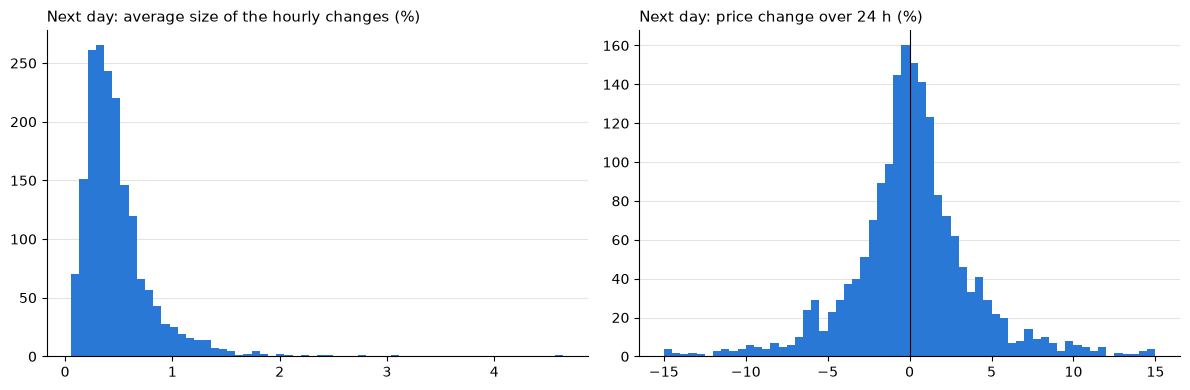

Share of up days in training: 0.511


,train size_next,train ret_next,val size_next,val ret_next
size_1d,0.688,0.029,0.540,0.041
range_1d,0.675,0.043,0.530,0.032
vol_1d,0.648,0.027,0.492,0.052
vol_7d,0.626,0.037,0.467,0.042
volume_ratio,0.199,0.010,0.226,0.000
ret_30d,-0.022,0.001,0.212,0.021
ret_1d,-0.137,-0.084,0.098,-0.058
ret_7d,-0.164,0.010,0.147,0.041
last_hour,-0.166,-0.069,-0.007,-0.022


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train_days["size_next"], bins=60, color=BLUE)
tidy(axes[0], "Next day: average size of the hourly changes (%)")
axes[1].hist(train_days["ret_next"].clip(-15, 15), bins=60, color=BLUE)
axes[1].axvline(0, color="black", lw=0.8)
tidy(axes[1], "Next day: price change over 24 h (%)")
plt.tight_layout()
plt.show()

print("Share of up days in training:", round(train_days["up_next"].mean(), 3))
corr_next = pd.DataFrame({
    f"{block} {t}": d[num_cols].corrwith(d[t])
    for block, d in [("train", train_days), ("val", val_days)] for t in ["size_next", "ret_next"]
})
corr_next.round(3).sort_values("train size_next", ascending=False)

**What we see** *(`course-methods.ipynb`, on train 2018–2023)*

- The price went up on **50.9 %** of the training days, so up and down days are almost equally common (the classes are balanced).
- The move size is skewed: most days are calm (median 0.35 % per hour), a few are very wild (up to 4.6 %).
- **Move size:** today's volatility attributes are strongly correlated with tomorrow's move size: `size_1d` 0.72, `range_1d` 0.69, `vol_1d` 0.68. Wild days tend to be followed by wild days ("volatility clustering").
- **Direction:** no attribute is correlated with tomorrow's direction. All correlations with `ret_next` are between −0.08 and +0.04.

This already suggests the answer: the **size** can be predicted, the **direction** hardly at all.

### 6.1 What kind of day was it? K-Means clusters

K-Means groups days by how the market behaved, **without** looking at the next day. Three attributes are used: the day's price change, its volatility and its volume compared with the week. They are standardised first, because K-Means uses distances.

**How many clusters?** The elbow method:

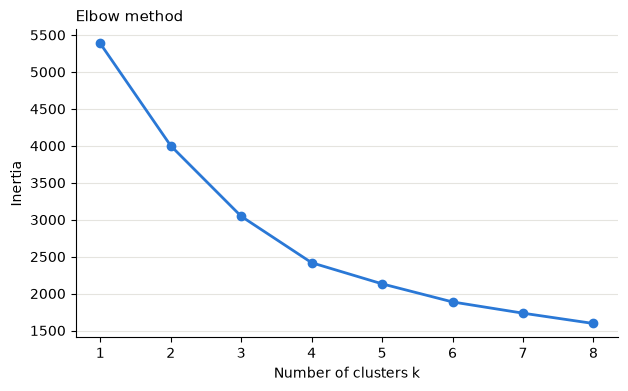

In [17]:
cluster_cols = ["ret_1d", "vol_1d", "volume_ratio"]
cluster_scaler = StandardScaler().fit(train_days[cluster_cols])
Z_train = cluster_scaler.transform(train_days[cluster_cols])

inertias = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z_train).inertia_ for k in range(1, 9)]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, 9), inertias, "o-", color=BLUE, lw=2)
ax.set_xlabel("Number of clusters k")
ax.set_ylabel("Inertia")
tidy(ax, "Elbow method")
plt.show()

**k = 4** (where the curve bends in `course-methods.ipynb`). Each cluster is described by its centre in the original units. The cluster numbers depend on the run, so name them from the centres.

,ret_1d,vol_1d,volume_ratio,days (train)
0,0.046,0.540,0.027,897
1,-6.125,1.305,0.385,197
2,0.112,0.462,-0.688,500
3,6.432,1.207,0.276,201


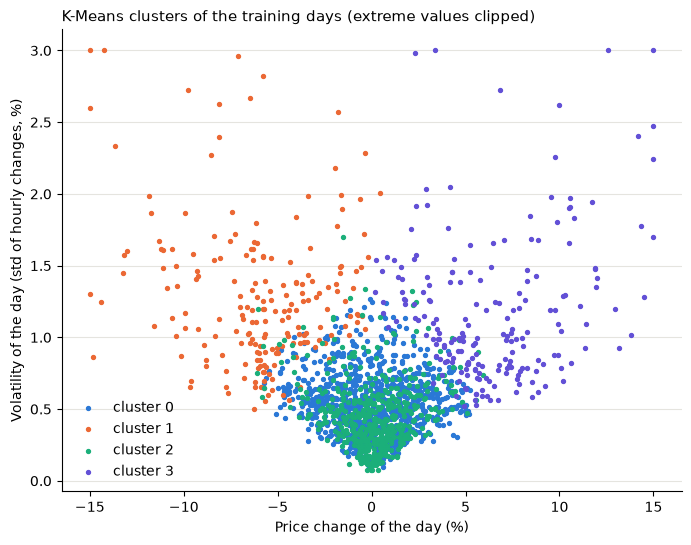

In [18]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(Z_train)

centres = pd.DataFrame(cluster_scaler.inverse_transform(kmeans.cluster_centers_), columns=cluster_cols)
centres["days (train)"] = np.bincount(kmeans.labels_)
display(centres.round(3))

cluster_colors = [BLUE, ORANGE, AQUA, "#6250d6"]
fig, ax = plt.subplots(figsize=(8, 6))
for k in range(4):
    part = train_days[kmeans.labels_ == k]
    ax.scatter(part["ret_1d"].clip(-15, 15), part["vol_1d"].clip(upper=3), s=8, color=cluster_colors[k], label=f"cluster {k}")
ax.set_xlabel("Price change of the day (%)")
ax.set_ylabel("Volatility of the day (std of hourly changes, %)")
ax.legend(frameon=False)
tidy(ax, "K-Means clusters of the training days (extreme values clipped)")
plt.show()

**Do the clusters say anything about the next day?** The validation days are assigned to the clusters learned on the training days, and the next day is compared:

In [19]:
val_clusters = kmeans.predict(cluster_scaler.transform(val_days[cluster_cols]))
summary = {}
for block, d, labels in [("train", train_days, kmeans.labels_), ("validation", val_days, val_clusters)]:
    summary[block] = d.assign(cluster=labels).groupby("cluster").agg(
        days=("up_next", "size"), next_day_move_size=("size_next", "mean"), next_day_up_share=("up_next", "mean"))
pd.concat(summary, axis=1).round(3)

train                                      validation  \
         days next_day_move_size next_day_up_share       days   
cluster                                                         
0         897              0.409             0.514        319   
1         197              0.809             0.604         20   
2         500              0.398             0.484        175   
3         201              0.709             0.478         33   

                                              
        next_day_move_size next_day_up_share  
cluster                                       
0                    0.290             0.495  
1                    0.504             0.650  
2                    0.266             0.514  
3                    0.461             0.485

**What we see** *(`course-methods.ipynb`, train 2018–2023, test 2024+)*

- **Elbow:** the inertia falls quickly up to k = 4 and slowly after that, so 4 clusters is a reasonable choice.
- **The 4 clusters** are easy to name from their centres:
  - **crash days:** −6.0 %, high volatility, high volume (213 training days);
  - **quiet days:** +0.2 %, low volatility, volume well below the weekly average (589);
  - **rally days:** +5.8 %, high volatility, high volume (293);
  - **normal days:** −0.3 %, average volatility and volume (1,089, the largest group).
- **The scatter plot:** the clusters are separated mainly by the day's price change (left = crash, right = rally) and by volatility (bottom = quiet).

**The next day:**
- **Move size depends on the cluster:** after crash days the next day's moves are almost **twice as big** (0.54 %) as after quiet days (0.29 %). The clustering found real market regimes, and the regime carries over to the next day.
- **Direction does not:** the share of up days is 49–54 % in every cluster. Even "crash" days are not followed by more down days (or more rebounds) than other days. The crash cluster had only 36 test days, so its 52.8 % is very uncertain.

Clustering is unsupervised: K-Means never saw the targets, yet it found groups that differ in tomorrow's move size, but not in tomorrow's direction.

### 6.2 Volatility and trend regimes

*Idea from `bitcoin-models-v3.ipynb` (D4), here without any model.* The days are split by two conditions that are **known at the forecast origin**: the tercile of last week's volatility (`vol_7d`, cut points from the train days) and the 30-day trend (bull if the price rose over the last 30 days). For each regime: how big the next day's moves are, how often the next day is up, and whether today's change says anything about tomorrow's.

In [20]:
vol_cut = train_days["vol_7d"].quantile([1 / 3, 2 / 3]).values


def regime_table(d):
    vol = pd.Series(pd.cut(d["vol_7d"], [-np.inf, *vol_cut, np.inf], labels=["1 calm", "2 middle", "3 wild"]).astype(str), index=d.index)
    trend = pd.Series(np.where(d["ret_30d"] > 0, "bull (30d up)", "bear (30d down)"), index=d.index)
    rows = {}
    for kind, labels in [("volatility", vol), ("trend", trend)]:
        for lab in sorted(labels.unique()):
            g = d[labels == lab]
            rows[f"{kind}: {lab}"] = {"days": len(g), "next_day_move_size": g["size_next"].mean(),
                                      "next_day_up_share": g["up_next"].mean(),
                                      "corr(ret_1d, ret_next)": g["ret_1d"].corr(g["ret_next"])}
    return pd.DataFrame(rows).T


pd.concat({"train": regime_table(train_days), "validation": regime_table(val_days)}, axis=1).round(3)

train                                       \
                         days next_day_move_size next_day_up_share   
volatility: 1 calm      599.0              0.300             0.506   
volatility: 2 middle    598.0              0.440             0.505   
volatility: 3 wild      598.0              0.711             0.523   
trend: bear (30d down)  903.0              0.495             0.506   
trend: bull (30d up)    892.0              0.471             0.517   

                                              validation                     \
                       corr(ret_1d, ret_next)       days next_day_move_size   
volatility: 1 calm                      0.020      428.0              0.269   
volatility: 2 middle                   -0.031       78.0              0.386   
volatility: 3 wild                     -0.138       41.0              0.466   
trend: bear (30d down)                 -0.138      195.0              0.261   
trend: bull (30d up)                   -0.023      352.0              0.322   

                                                                 
                       next_day_up_share corr(ret_1d, ret_next)  
volatility: 1 calm                 0.498                 -0.009  
volatility: 2 middle               0.474                 -0.061  
volatility: 3 wild                 0.659                 -0.254  
trend: bear (30d down)             0.503                 -0.050  
trend: bull (30d up)               0.509                 -0.077

**What we see** *(`bitcoin-models-v3.ipynb`, D4, with models on the test block)*

- "**The volatility model works in every regime.** Within each volatility tercile it still explains 34–38% of the day-to-day variation, while the naive rule is *negative* within each tercile (it only knows the level, not the day-to-day changes)."
- "**Hourly return IC** is ≈ 0 in every regime (−0.02 to +0.03): there is no hidden regime where returns become predictable."
- "**Direction accuracy** is 55.8% in the wild tercile, but 53.6% of those days were up days. Most of it is the base rate, not skill."

## 7. Other markets: Binance and ETH

*Descriptive, whole series.* The Binance hourly candles of BTCUSDT and ETHUSDT (`data/binance_*_1h.csv.gz`, from `utils/binance.py`) are a second source for Bitcoin and the main other crypto asset. Two questions:

1. **Does a second exchange agree with the base data?** Kaggle's data comes from Bitstamp (USD); Binance trades against USDT. If the hourly returns of both did not match, the base data would have a problem.
2. **How closely does ETH move with BTC, and does it lead it?**

`load_binance` fills the hours Binance has no data for (127 in 2018–2019) with the previous price, as in `v3-extensions.ipynb`.

In [21]:
bn_btc, bn_eth = load_binance("BTCUSDT"), load_binance("ETHUSDT")
both = pd.DataFrame({"btc_bitstamp": r, "btc_binance": bn_btc["ret"].reindex(r.index),
                     "eth": bn_eth["ret"].reindex(r.index)}).dropna()

diff = both["btc_bitstamp"] - both["btc_binance"]
print(f"Common hours: {len(both):,}   {both.index[0]} -> {both.index[-1]}")
print(f"corr(Bitstamp, Binance) hourly BTC returns: {both['btc_bitstamp'].corr(both['btc_binance']):.4f}")
print(f"mean |difference| {diff.abs().mean():.3f} pp, against an average |move| of {both['btc_bitstamp'].abs().mean():.3f}%; "
      f"hours differing by more than 1 pp: {(diff.abs() > 1).sum()}")

eth_years = {}
for y, d in both.groupby(both.index.year):
    eth_years[y] = {"corr BTC-ETH returns": d["btc_bitstamp"].corr(d["eth"]),
                    "corr BTC-ETH |returns|": d["btc_bitstamp"].abs().corr(d["eth"].abs()),
                    "ETH / BTC average |move|": d["eth"].abs().mean() / d["btc_bitstamp"].abs().mean()}
display(pd.DataFrame(eth_years).T.round(3))

Common hours: 76,851   2018-01-01 00:00:00 -> 2026-10-08 02:00:00
corr(Bitstamp, Binance) hourly BTC returns: 0.9821
mean |difference| 0.054 pp, against an average |move| of 0.416%; hours differing by more than 1 pp: 162


,corr BTC-ETH returns,corr BTC-ETH |returns|,ETH / BTC average |move|
2018,0.801,0.756,1.411
2019,0.752,0.675,1.227
2020,0.823,0.782,1.353
2021,0.832,0.756,1.270
2022,0.890,0.845,1.362
2023,0.854,0.812,1.116
2024,0.808,0.746,1.208
2025,0.802,0.723,1.637
2026,0.887,0.836,1.282


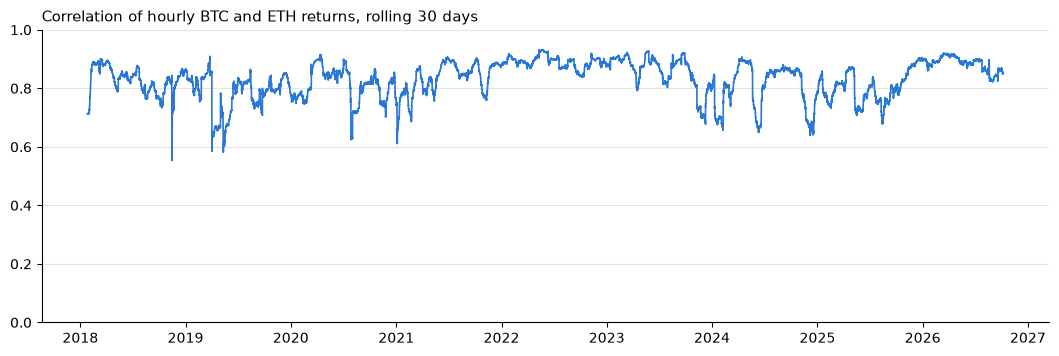

k (hours),-3,-2,-1,0,1,2,3
ETH,-0.0031,-0.0384,-0.0207,0.8168,0.0010,-0.0313,-0.0012
BTC itself,0.0014,-0.0380,-0.0237,NaN,-0.0237,-0.0380,0.0014


In [22]:
roll_eth = both["btc_bitstamp"].rolling(720, min_periods=600).corr(both["eth"])
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(roll_eth.index, roll_eth, color=BLUE, lw=1.2)
ax.set_ylim(0, 1)
tidy(ax, "Correlation of hourly BTC and ETH returns, rolling 30 days")
plt.show()

# Lead-lag on the train block: corr(BTC_t, X_{t-k}); k > 0 means X leads BTC by k hours
tr = both.loc[:TRAIN_END]
lead = pd.DataFrame({
    "ETH": {k: tr["btc_bitstamp"].corr(tr["eth"].shift(k)) for k in range(-3, 4)},
    "BTC itself": {k: tr["btc_bitstamp"].corr(tr["btc_bitstamp"].shift(k)) if k else np.nan for k in range(-3, 4)},
})
lead.index.name = "k (hours)"
lead.round(4).T

**What we see** *(`v3-extensions.ipynb`, section 2 and conclusions)*

"The Binance attributes do not change the result. Gradient Boosting on Alberto's base features reaches test R² **0.123**; with order flow, ETH or ETH vs BTC it stays between 0.121 and 0.126. On validation the differences are also ≤ 0.002, smaller than the effect of a different hyperparameter setting. Ridge gets slightly *worse* with more attributes. The size of the next hours' moves is already described by Bitcoin's own recent volatility and the clock; ETH and order flow repeat the same information."

For the next hour's direction: "With the Binance attributes the AUC is the same (0.537)". The leak check of that notebook found a correlation of 0.9987 between Binance's hourly BTC change and the Kaggle one.

## 8. Macroeconomic variables

*Section and texts from `Correlation Analyses/correlation_analyses.ipynb` and its results brief (`BTC_macro_correlation_results_brief.docx`). The BTC frames now come from the base data, so the analysis starts in **2018** (it started in 2017 before).*

Measures how BTC returns relate to ~40 macro and market variables (FRED, Yahoo Finance) at daily, weekly and monthly frequency.

Flow: BTC frames → macro panels → remove redundant variables → correlations → lead-lag → stability over time.

**Summary of the brief** *(data 2017 → Oct 2026)*. "BTC returns correlate moderately with risk assets and financial conditions: positively with equities (Russell 2000, S&P 500), high-yield bond ETFs and net liquidity, and negatively with the VIX, the dollar, credit spreads and tighter financial conditions (NFCI). The strongest correlations are 0.26 to 0.27 in absolute value at daily and weekly frequency and 0.37 (S&P 500) at monthly frequency; the leading variables in each panel have q < 0.05. No variable leads BTC: correlations peak at k = 0 and are close to zero for k > 0. None is related to the size of BTC's moves. The relations are not stable: the S&P 500 correlation goes from near zero in 2017–2019 to 0.56 in 2022 and 0.44 in 2026."

Reference listed in the first version of the notebook: <https://arxiv.org/html/2407.13278v1>.

**Method** *(from the brief)*. Panels of log returns (rates and spreads as differences, computed after aligning to the panel frequency). Slow series (e.g. CPI) only enter slower panels (monthly); the daily panel uses weekdays only. Spearman correlation with the BTC return and with the return's absolute value; q-values from Benjamini–Hochberg false discovery rate correction. Lead-lag on an a-priori shortlist [SP500, DXY, US10Y, Gold, VIX, HY_OAS, NetLiquidity] (using availability-date alignment); stability checked with a sliding window.

### 8.1 Macro panels

Downloads the macro and market variables once and builds one panel per frequency, aligned by observation date (`pit=False`), so it measures co-movement rather than prediction. Each variable is transformed (log return or difference) after alignment, so slow series are never correlated with fine-grained data. Downloads are cached in `.macro_cache/`.

**Note.** In the last run of the correlation notebook **all 16 Yahoo Finance series failed to download** (S&P 500, Nasdaq, VIX, DXY, gold, oil…), so 4 of the 7 shortlisted variables were missing (README, task 9). The cell prints the skipped series: check it before reading the tables.

In [23]:
btc_close = {f: df["Close"] for f, df in frames_from_hourly(hourly).items()}
macro = load_raw(data_start=START)                          # downloads (or reads cache) once
panels, meta = build_panels(btc_close, macro, start=START)
print({f: p.shape for f, p in panels.items()})

Skipped series:
  yfinance: No module named 'yfinance'
  SP500: no data for ^GSPC
  NASDAQ: no data for ^IXIC
  Russell2000: no data for ^RUT
  EuroStoxx50: no data for ^STOXX50E
  Nikkei: no data for ^N225
  HangSeng: no data for ^HSI
  VIX: no data for ^VIX
  DXY: no data for DX-Y.NYB
  Gold: no data for GC=F
  Silver: no data for SI=F
  Copper: no data for HG=F
  WTI: no data for CL=F
  Brent: no data for BZ=F
  NatGas: no data for NG=F
  TLT: no data for TLT
  HYG: no data for HYG
{'D': (2288, 15), 'W': (457, 20), 'ME': (105, 30)}


**Data coverage.** Shows the variables with the lowest fraction of non-missing observations in their panel. Low coverage may mean truncated history (e.g. licensed series on FRED) or a discontinued series. Check this before interpreting any correlation.

In [24]:
cov = pd.concat([p.drop(columns=list(TARGETS)).notna().mean() for p in panels.values()])
cov = cov.groupby(level=0).first()                          # finest panel where each variable appears
cov.sort_values().head(10).to_frame("fraction_with_data").join(meta[["source", "id", "group"]])

,fraction_with_data,source,id,group
HY_OAS,0.339161,FRED,BAMLH0A0HYM2,credit
CPI,0.990476,FRED,CPIAUCSL,inflation
CoreCPI,0.990476,FRED,CPILFESL,inflation
ConsSentiment,0.990476,FRED,UMCSENT,activity
IndProd,0.990476,FRED,INDPRO,activity
M2,0.990476,FRED,M2SL,liquidity
CorePCE,0.990476,FRED,PCEPILFE,inflation
PCE,0.990476,FRED,PCEPI,inflation
Unemployment,0.990476,FRED,UNRATE,activity
RetailSales,0.990476,FRED,RSAFS,activity


### 8.2 Redundancy among macro variables

*(From `old_notebooks/correlation_analyses.ipynb`.)* First a look at how the macro variables relate to each other: the Spearman correlation between every pair of variables of the daily panel, ordered by hierarchical clustering (distance 1 − |r|) so that redundant variables sit next to each other. BTC is not in the plot.

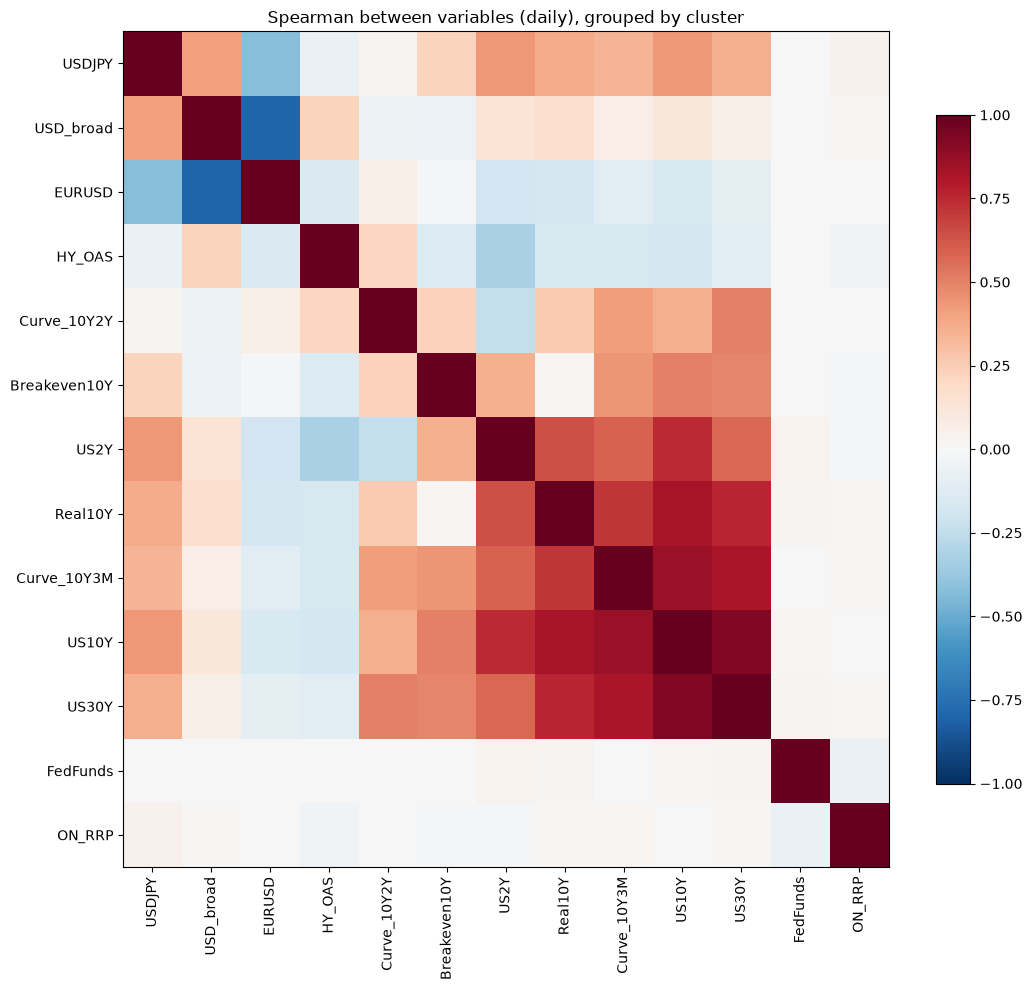

In [25]:
c = panels["D"].drop(columns=list(TARGETS)).corr(method=METHOD)
order = cluster_order(c)
heatmap(c.loc[order, order], "Spearman between variables (daily), grouped by cluster", vmax=1, annot=False, figsize=(11, 10))
plt.show()

The pruning below removes variables that are almost duplicates of another macro variable (|r| above `PRUNE_THRESHOLD`), keeping the one that is less redundant with the rest. that are almost duplicates of another macro variable (|r| above `PRUNE_THRESHOLD`), keeping the one that is less redundant with the rest. Only the correlation between macro variables is used, never the one with BTC, so the pruning does not bias the results interpreted below. When two variables are redundant, the one in `FOCUS` is kept. The table lists what was dropped and which variable stands in for it.

In [26]:
panels, pruned = prune_panels(panels, threshold=PRUNE_THRESHOLD, method=METHOD, prefer=FOCUS)
display(pruned.round(2))
print({f: p.shape[1] - len(TARGETS) for f, p in panels.items()}, "variables kept per panel")

,kept_instead,abs_r,panel
US30Y,US10Y,0.93,D
Curve_10Y3M,US10Y,0.86,D
Real10Y,US10Y,0.82,D
CPI,PCE,0.86,ME
PCE,CorePCE,0.80,ME


{'D': 10, 'W': 15, 'ME': 23} variables kept per panel


### 8.3 Correlations with BTC

Ranks every remaining variable by its correlation with the BTC return (`r_ret`) and with its absolute value (`r_abs`), i.e. the size of the move rather than its direction. `q_*` is the p-value adjusted for multiple comparisons (FDR): with this many variables, several would look significant by chance alone. Monthly results rest on ~100 observations, so treat them with extra caution.

In [27]:
for f, name in {"D": "DAILY (weekdays)", "W": "WEEKLY", "ME": "MONTHLY"}.items():
    print(f"\n=== {name} ===")
    display(corr_summary(panels[f], METHOD).round(3).head(TOP))


=== DAILY (weekdays) ===


,n,r_ret,q_ret,r_abs,q_abs
var,,,,,
HY_OAS,776,-0.255,0.000,-0.017,0.716
USD_broad,2287,-0.165,0.000,-0.019,0.570
EURUSD,2287,0.128,0.000,0.037,0.375
Breakeven10Y,2287,0.078,0.000,-0.025,0.463
USDJPY,2287,-0.044,0.072,-0.027,0.463
Curve_10Y2Y,2287,0.039,0.103,0.018,0.570
US2Y,2287,-0.017,0.511,-0.045,0.307
FedFunds,2287,0.017,0.511,0.005,0.812
ON_RRP,2287,0.009,0.723,0.010,0.716



=== WEEKLY ===


,n,r_ret,q_ret,r_abs,q_abs
var,,,,,
HY_OAS,154,-0.287,0.002,0.109,0.446
NFCI,456,-0.195,0.000,0.103,0.184
Breakeven10Y,456,0.154,0.005,-0.092,0.184
USD_broad,456,-0.145,0.007,0.028,0.637
EURUSD,456,0.112,0.050,-0.032,0.612
ON_RRP,456,-0.075,0.279,0.039,0.612
FedFunds,456,-0.059,0.451,-0.074,0.349
FedBalanceSheet,456,-0.052,0.504,0.132,0.073
US10Y,456,0.042,0.591,-0.013,0.783



=== MONTHLY ===


,n,r_ret,q_ret,r_abs,q_abs
var,,,,,
Breakeven10Y,104,0.364,0.003,-0.089,0.806
NFCI,104,-0.323,0.009,-0.026,0.896
NetLiquidity,104,0.310,0.010,0.154,0.631
USD_broad,104,-0.225,0.119,-0.070,0.863
ON_RRP,104,-0.209,0.146,-0.065,0.863
Jobless_claims,104,-0.198,0.160,0.096,0.806
FedFunds,104,-0.155,0.313,0.045,0.896
IndProd,104,0.148,0.313,0.041,0.896
EURUSD,104,0.146,0.313,0.025,0.896


**What we see** *(results brief, data from 2017, with the Yahoo Finance series available)*

"Sample: 2,550 daily (weekdays), 511 weekly and 117 monthly observations, from January 2017 to October 2026." Table 1 of the brief, the strongest Spearman correlations with the BTC return ((!) = partial history):

| Frequency | Variable | n | r_ret | q_ret | r_abs | q_abs |
|---|---|---|---|---|---|---|
| Daily | Russell2000 | 2550 | 0.257 | <0.001 | −0.037 | 0.256 |
| Daily | HY_OAS | 783 (!) | −0.256 | <0.001 | −0.020 | 0.702 |
| Daily | SP500 | 2550 | 0.236 | <0.001 | −0.037 | 0.256 |
| Weekly | HY_OAS | 156 (!) | −0.272 | 0.002 | 0.123 | 0.484 |
| Weekly | Russell2000 | 511 | 0.257 | <0.001 | −0.046 | 0.625 |
| Weekly | VIX | 511 | −0.231 | <0.001 | 0.057 | 0.486 |
| Monthly | SP500 | 117 | 0.366 | 0.002 | 0.136 | 0.493 |
| Monthly | NFCI | 117 | −0.322 | 0.008 | −0.027 | 0.893 |
| Monthly | HYG | 117 | 0.287 | 0.017 | 0.103 | 0.706 |

"The strongest relations are with risk assets and financial conditions. BTC returns move with equities and high-yield credit (Russell 2000, S&P 500, HYG) and against the VIX, the dollar and credit spreads (HY_OAS).

All the leading daily variables have q < 0.001, but the correlations are moderate. Weekly results are similar. In the monthly panel the S&P 500 is the strongest (r = 0.37, q = 0.002), followed by NFCI, HYG, net liquidity and Russell 2000, all with q < 0.05; the VIX (r = −0.23, q = 0.061) does not reach that level, and monthly results rest on only 117 observations. HY_OAS appears among the top rows of the daily and weekly tables but covers only the period since 2023 (783 and 156 observations), so it cannot be compared directly with the rest. No variable is related to the size of BTC's moves: among the 12 strongest variables of each panel, q_abs is at least 0.22."

*(README, last run without Yahoo Finance)* "High-yield spread −0.26 daily, but only 31% data coverage. NFCI −0.19 weekly and −0.32 monthly. Broad dollar −0.15 daily. Net liquidity +0.29 monthly."

### 8.4 Lead-lag

Uses panels built with `pit=True` (availability date), so each value only appears when it was actually known, for the shortlist in `FOCUS` (variables pruned above are replaced by the one kept instead). Shows the correlation between BTC returns and each variable shifted by k periods; k > 0 means the variable leads BTC. A stronger correlation at k > 0 than at k = 0 would suggest predictive content; a peak only at k = 0 is just co-movement.

focus variable not available: SP500
focus variable not available: DXY
focus variable not available: Gold
focus variable not available: VIX


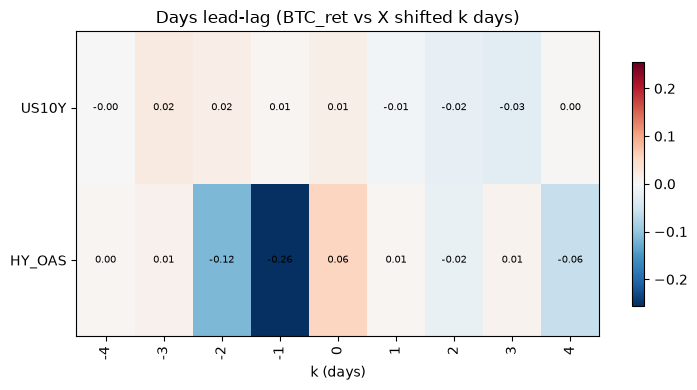

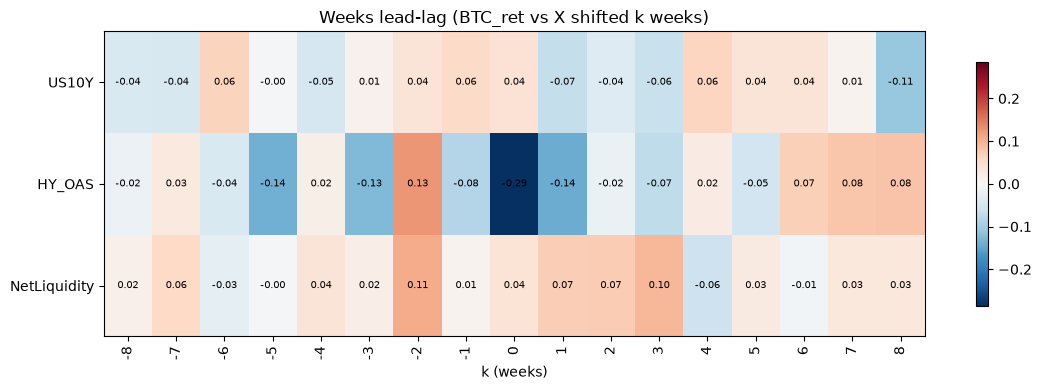

In [28]:
focus = resolve_focus(FOCUS, panels, pruned)
kept = sorted({c for p in panels.values() for c in p.columns} - set(TARGETS))
panels_pit, _ = build_panels(btc_close, macro, pit=True, freqs=tuple(MAX_LAG), start=START, variables=kept)

units = {"D": "days", "W": "weeks"}
for f, k in MAX_LAG.items():
    vars_f = [v for v in focus if v in panels_pit[f].columns]
    heatmap(lead_lag(panels_pit[f], max_lag=k, variables=vars_f, method=METHOD),
            f"{units[f].capitalize()} lead-lag (BTC_ret vs X shifted k {units[f]})", xlabel=f"k ({units[f]})")
plt.show()

**What we see** *(results brief)*

"At the daily frequency every variable peaks at k = 0 (S&P 500 0.24, VIX −0.20, DXY −0.13, Gold 0.11) and all values at k > 0 are within ±0.06, so none of them leads BTC. HY_OAS peaks at k = −1 (−0.26): this is its same-day correlation, shifted by one position by its two-day publication lag, and it is close to zero at k = 0 (0.06). The weekly panel gives the same picture: the strongest cells are at k = 0 (HY_OAS −0.27, S&P 500 0.23, VIX −0.23), and the largest cell with k > 0 is HY_OAS at k = 1 (−0.13, n = 156), which is below the 5% significance level for 156 observations even before correcting for the 63 cells tested."

### 8.5 Stability over time

Tests whether the correlation with BTC stays similar through time or changes between regimes, for the same shortlist (daily panel). Plots a rolling correlation (Pearson, absolute value) and tabulates the Spearman correlation per calendar year. With ~250 daily observations per year, small differences between years may be noise rather than a real regime change.

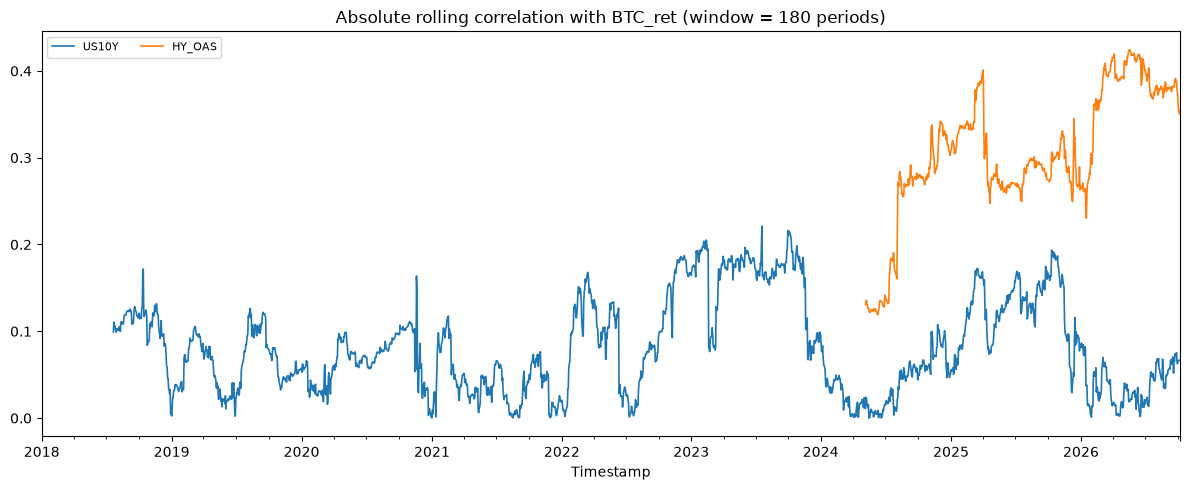

,US10Y,HY_OAS
2018,0.09,NaN
2019,-0.02,NaN
2020,0.08,NaN
2021,0.06,NaN
2022,-0.06,NaN
2023,-0.06,-0.18
2024,0.01,-0.17
2025,0.08,-0.30
2026,-0.16,-0.33


In [29]:
vars_d = [v for v in focus if v in panels["D"].columns]
rolling_corr_plot(panels["D"], vars_d, window=ROLL_WINDOW, absolute=True)
plt.show()
corr_by_year(panels["D"], vars_d, method=METHOD).round(2)

**What we see** *(results brief)*

"The relations are not stable. The rolling correlation with the S&P 500 and the VIX, which move together, rises from low values (mostly below 0.2) in 2017–2019 to 0.4–0.6 in 2020 and 2022–2023, falls to about 0.1–0.2 in early 2024 and returns to 0.4–0.55 in 2025–2026. The yearly Spearman correlations confirm this: the S&P 500 goes from 0.04, 0.05 and −0.02 (2017–2019) to 0.56 in 2022 and 0.44 in 2026, with the opposite sign for the VIX (−0.49 in 2022); DXY is negative in most years (−0.32 in 2022), US10Y stays close to zero (−0.15 to 0.09), Gold is strong only in some years (0.31 in 2020, 0.33 in 2026) and HY_OAS, available since 2023, ranges from −0.17 to −0.34. The abrupt jumps in the rolling lines (for example in March 2020) are single extreme days entering or leaving the window, a known sensitivity of the Pearson correlation used in this plot. Drops in correlation for some variables coincide with rises in others (in late 2020 the S&P 500 falls from about 0.53 to 0.25 while DXY rises from about 0.1 to 0.3), but the S&P 500 and the VIX move together, so they largely reflect a single risk-appetite factor."

## 9. Conclusions

*Copied from the archived notebooks and the correlation brief; the source is named in each block. The numbers are from those runs: compare them with the outputs above after running this notebook.*

### 9.1 The data *(README data-quality check, `hourly-base-data.ipynb`)*

- Since 2018 the series is complete: 76,851 consecutive hours, with 15 outages of an hour or more flagged (`filled_minutes`, `no_trade`) rather than removed.
- The hours with moves above 10% are real events (COVID crash of 12–13 Mar 2020, crash of 19 May 2021, Musk's tweet of 29 Jan 2021), not data errors. **The data is clean. The noise is the market itself, not a data-quality problem**, so it cannot be "cleaned away". It can only be handled with robust losses, volatility scaling and aggregated targets.
- The price level is not stationary: later prices lie outside the training range, so models need scale-free features (returns, ratios, volatility). Volatility also changes a lot between periods, so errors are reported relative to a baseline.

### 9.2 Direction and size of the hourly moves *(`bitcoin-models-v3.ipynb`, conclusions)*

"The **direction** of hourly Bitcoin moves *is* almost pure noise. The only dependence in hourly returns is a tiny reversal at lags 1, 2 and 24 hours: statistically real, but able to explain at most ≈0.4% of the variance, and not stable from one period to the next."

"The *size* of hourly moves is strongly autocorrelated (0.27 at lag 1, still 0.10 after a week) and follows the clock (1.5× between the busiest and quietest hour; weekends 0.8×)."

*(`v3-extensions.ipynb`)* The lag-1 reversal still gives a small signal for **the next hour only**: AUC 0.537, 55% correct on the 10% most confident forecasts (p < 10⁻⁴). Hours 2–24 stay a coin flip.

### 9.3 Drift *(`v3-extensions.ipynb`)*

"Bitcoin's behaviour drifts (e.g. the new 14 UTC volatility peak since the ETFs), so **keeping models and calibrations up to date matters more than extra data sources**."

### 9.4 Volatility clustering and regimes *(`course-methods.ipynb`)*

- "**How big will tomorrow's moves be?** Predictable. The key information is today's volatility: calm days follow calm days, and wild days follow wild days."
- "K-Means finds four clear regimes (crash, rally, quiet and normal days). The regime tells us how big the next day's moves will be, but not their direction."
- *(`bitcoin-models-v3.ipynb`)* "**No hidden regime** makes returns predictable."

### 9.5 Other markets *(`v3-extensions.ipynb`)*

"**Binance order flow and ETH do not help**: neither for the move size (R² 0.121–0.126 vs 0.123) nor for the next-hour direction (AUC 0.537 with and without them)." The size of the next hours' moves is already described by Bitcoin's own recent volatility and the clock.

### 9.6 Macroeconomic variables *(correlation results brief)*

"Between 2017 and 2026, BTC returns co-move with global risk appetite: positively with equities, high-yield bond ETFs and net liquidity, and negatively with the VIX, the dollar, credit spreads and tighter financial conditions. The relations are moderate (|r| up to 0.26 daily and 0.37 monthly), stronger in some periods (2020–2023, 2025–2026) than in others, and contemporaneous: no variable leads BTC and none is related to the size of its moves. The evidence supports an association with risk appetite, not a predictive relation or a causal one."

Limitations:
- "Correlation is not causation; lead-lag results are exploratory and not an out-of-sample trading test."
- "Economic series are revised after publication; final values with approximate lags were used (ALFRED vintages would be needed)."
- "Monthly sample is small and p-values assume independent observations; some series have partial history."
- "Spearman captures only monotonic relations; the pruning threshold, start date and shortlist are analyst choices."

### 9.7 What it means for the models *(`bitcoin-models-v3.ipynb`, recommended story)*

"Hourly Bitcoin returns are close to a random walk: their direction carries less than 1% predictable variance, and no amount of model tuning makes it reliably predictable. Asking the questions the data *can* answer changes everything: [...] volatility is predictable, direction is not, and a good forecast still needs a good decision rule to be useful."